# Retail Sales Forecasting
**Internship project (Advanced) | CognoRise InfoTech**

**Dataset:** Walmart Recruiting - Store Sales Forecasting (Kaggle): `train.csv`, `stores.csv`, `features.csv`
**Goal:** Forecast weekly sales for each store and department, and turn the results into inventory and sales-planning recommendations.

**Key design choices :**
1. **Time-based split.** We train on the past and test on the most recent weeks. A random split would let the model see the future (data leakage).
2. **Lag features** (sales 1, 2, 4 and 52 weeks ago) are built per store-department, using only earlier weeks.
3. **Baselines first.** A model is only useful if it beats "same as last week" and "same as last year".
4. **Metrics:** MAE, RMSE and the competition's weighted MAE (holiday weeks count 5x).


In [2]:
def read_table(name):
    # Kaggle gives train/features as .csv.zip; pandas reads either form
    for candidate in (name, name + ".zip"):
        if os.path.exists(candidate):
            return pd.read_csv(candidate)
    raise FileNotFoundError(f"Could not find {name} or {name}.zip in this folder")

train = read_table("train.csv")
stores = read_table("stores.csv")
features = read_table("features.csv")

for t in (train, features):
    t["Date"] = pd.to_datetime(t["Date"])

print("train   :", train.shape, "| dates", train["Date"].min().date(), "to", train["Date"].max().date())
print("stores  :", stores.shape)
print("features:", features.shape)
train.head()

train   : (421570, 5) | dates 2010-02-05 to 2012-10-26
stores  : (45, 3)
features: (8190, 12)


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


In [3]:
df = (train
      .merge(stores, on="Store", how="left")
      .merge(features, on=["Store", "Date", "IsHoliday"], how="left"))
print("Merged shape:", df.shape)
print("Rows without store info:", df["Type"].isna().sum())
df.head()

Merged shape: (421570, 16)
Rows without store info: 0


,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment
0,1,1,2010-02-05,24924.50,False,A,151315,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106
1,1,1,2010-02-12,46039.49,True,A,151315,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106
2,1,1,2010-02-19,41595.55,False,A,151315,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106
3,1,1,2010-02-26,19403.54,False,A,151315,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106
4,1,1,2010-03-05,21827.90,False,A,151315,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106


## 2. Data cleaning
Steps: check duplicates and missing values, handle negative sales, fill missing markdowns, and make the sorting and types consistent.

In [4]:
print("Duplicate (Store, Dept, Date) rows:", df.duplicated(["Store", "Dept", "Date"]).sum())
print()
print("Missing values:")
miss = df.isna().sum()
print(miss[miss > 0])
print()
neg = (df["Weekly_Sales"] < 0).sum()
print(f"Negative weekly sales: {neg} rows ({neg / len(df):.2%}), these are returns/adjustments")
print("Zero weekly sales:", (df["Weekly_Sales"] == 0).sum())

Duplicate (Store, Dept, Date) rows: 0

Missing values:
MarkDown1    270889
MarkDown2    310322
MarkDown3    284479
MarkDown4    286603
MarkDown5    270138
dtype: int64

Negative weekly sales: 1285 rows (0.30%), these are returns/adjustments
Zero weekly sales: 73


In [5]:
df = df.drop_duplicates(["Store", "Dept", "Date"]).copy()

# 1. Negative sales are returns: clip to 0 so they do not distort percentage-style measures
df["Weekly_Sales"] = df["Weekly_Sales"].clip(lower=0)

# 2. MarkDown columns are empty before Nov 2011 (the promotions were not recorded): treat as 0
markdown_cols = [f"MarkDown{i}" for i in range(1, 6)]
df[markdown_cols] = df[markdown_cols].fillna(0)

# 3. CPI / Unemployment / Temperature / Fuel price: forward-fill within each store, then fall back to the median
df = df.sort_values(["Store", "Dept", "Date"]).reset_index(drop=True)
for col in ["CPI", "Unemployment", "Temperature", "Fuel_Price"]:
    df[col] = df.groupby("Store")[col].ffill()
    df[col] = df[col].fillna(df[col].median())

df["IsHoliday"] = df["IsHoliday"].astype(int)
print("Remaining missing values:", int(df.isna().sum().sum()))
print("Stores:", df["Store"].nunique(), "| Departments:", df["Dept"].nunique(),
      "| Weeks:", df["Date"].nunique())

Remaining missing values: 0
Stores: 45 | Departments: 81 | Weeks: 143


In [6]:
# Name the holiday weeks (dates from the competition description)
holiday_dates = {
    "Super Bowl": ["2010-02-12", "2011-02-11", "2012-02-10", "2013-02-08"],
    "Labor Day": ["2010-09-10", "2011-09-09", "2012-09-07", "2013-09-06"],
    "Thanksgiving": ["2010-11-26", "2011-11-25", "2012-11-23", "2013-11-29"],
    "Christmas": ["2010-12-31", "2011-12-30", "2012-12-28", "2013-12-27"],
}
date_to_holiday = {pd.Timestamp(d): name for name, ds in holiday_dates.items() for d in ds}
df["HolidayName"] = df["Date"].map(date_to_holiday).fillna("None")

# Weekly total across all stores (used for the time-series views)
weekly = df.groupby("Date")["Weekly_Sales"].sum()
weekly_holiday = df.groupby("Date")["IsHoliday"].max()
print(df["HolidayName"].value_counts())

HolidayName
None            391909
Super Bowl        8895
Labor Day         8861
Thanksgiving      5959
Christmas         5946
Name: count, dtype: int64


## 3. Exploratory data analysis

### 3.1 Total weekly sales over time

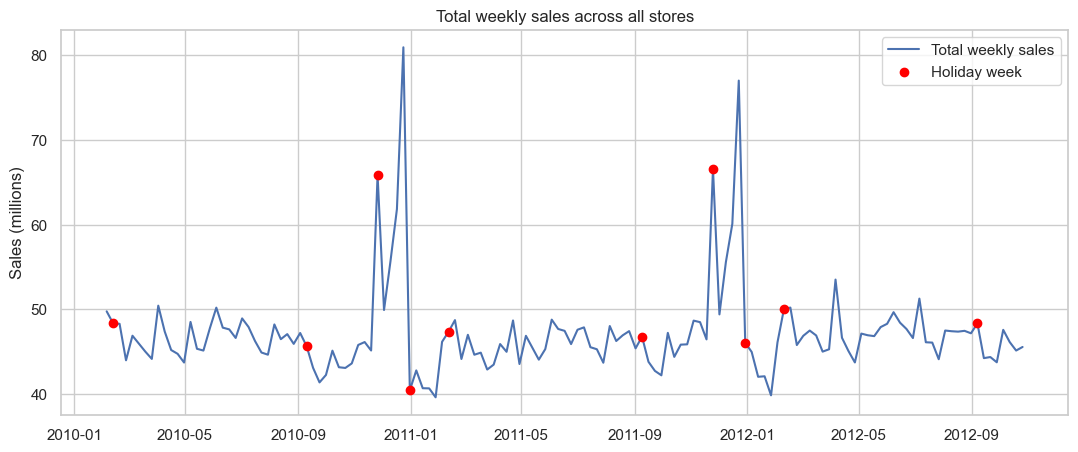

In [7]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(weekly.index, weekly.values / 1e6, label="Total weekly sales")
hol = weekly[weekly_holiday == 1]
ax.scatter(hol.index, hol.values / 1e6, color="red", zorder=3, label="Holiday week")
ax.set_title("Total weekly sales across all stores")
ax.set_ylabel("Sales (millions)")
ax.legend()
plt.savefig("outputs/01_total_sales_trend.png", dpi=150, bbox_inches="tight")
plt.show()

Interpretation: Most weeks have total sales of about 40 to 50 million. There are big spikes every year in late November and December. The highest week is about 81 million, just before Christmas 2010. The pattern repeats each year.

### 3.2 Seasonality

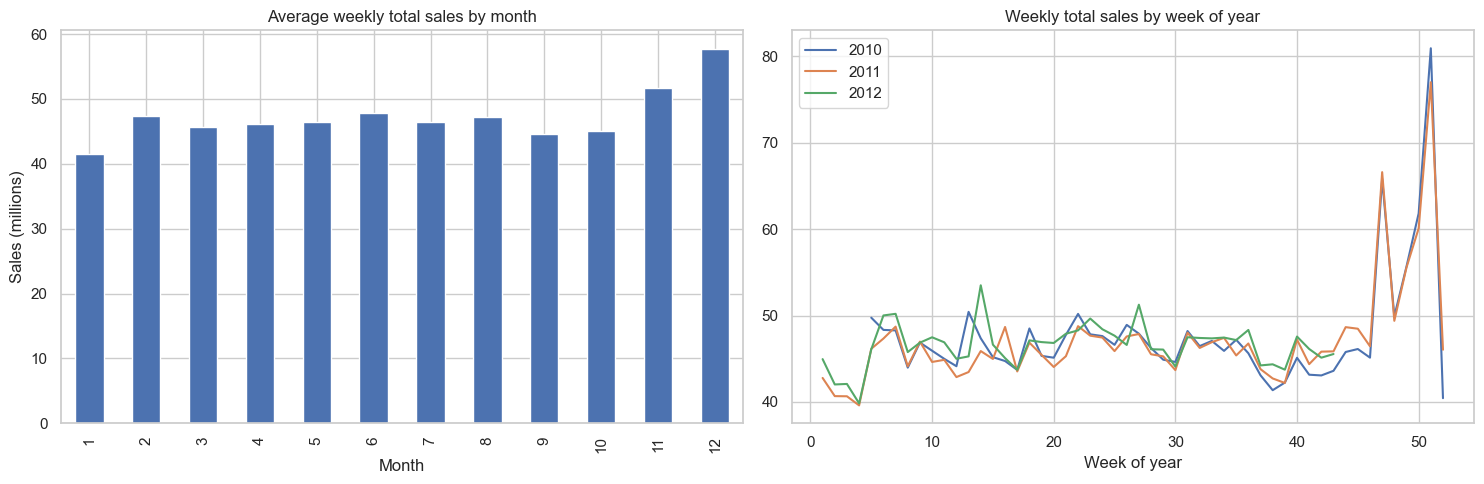

In [8]:
wk = weekly.to_frame("sales")
wk["Month"] = wk.index.month
wk["WeekOfYear"] = wk.index.isocalendar().week.astype(int)
wk["Year"] = wk.index.year

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
wk.groupby("Month")["sales"].mean().div(1e6).plot(kind="bar", ax=axes[0])
axes[0].set_title("Average weekly total sales by month")
axes[0].set_ylabel("Sales (millions)")

for yr, g in wk.groupby("Year"):
    axes[1].plot(g["WeekOfYear"], g["sales"] / 1e6, label=str(yr))
axes[1].set_title("Weekly total sales by week of year")
axes[1].set_xlabel("Week of year")
axes[1].legend()
plt.tight_layout()
plt.savefig("outputs/02_seasonality.png", dpi=150, bbox_inches="tight")
plt.show()

Interpretation: December is the strongest month (about 58 million a week), then November (about 52 million). January is the weakest (about 42 million). The three years follow the same shape, so sales are seasonal.

### 3.3 Holiday effect

               mean      median  count
Holiday                               
0        46857140.0  46128910.0    133
1        50530754.0  47833633.0     10


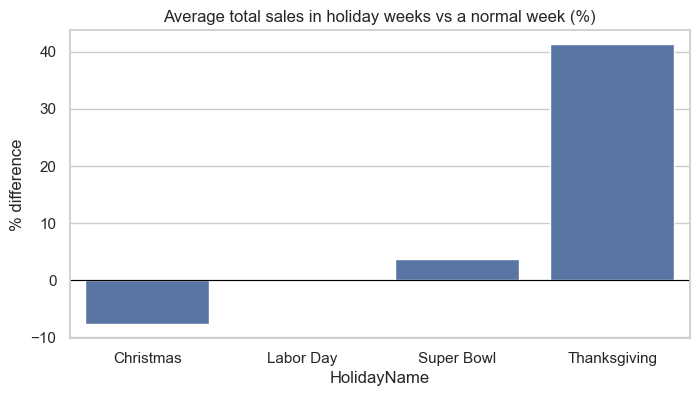

HolidayName
Christmas       -7.7
Labor Day        0.1
Super Bowl       3.6
Thanksgiving    41.3
Name: Weekly_Sales, dtype: float64

Mann-Whitney U test, holiday vs normal weeks: p-value = 0.0823


In [9]:
hol_stats = wk.assign(Holiday=weekly_holiday.values).groupby("Holiday")["sales"].agg(["mean", "median", "count"]).round(0)
print(hol_stats)

names = df.groupby(["Date", "HolidayName"])["Weekly_Sales"].sum().reset_index()
base = names.loc[names["HolidayName"] == "None", "Weekly_Sales"].mean()
effect = (names.groupby("HolidayName")["Weekly_Sales"].mean() / base - 1).drop("None", errors="ignore") * 100

plt.figure(figsize=(8, 4))
sns.barplot(x=effect.index, y=effect.values)
plt.axhline(0, color="black", lw=0.8)
plt.title("Average total sales in holiday weeks vs a normal week (%)")
plt.ylabel("% difference")
plt.savefig("outputs/03_holiday_effect.png", dpi=150, bbox_inches="tight")
plt.show()
print(effect.round(1))

# Statistical test
a = weekly[weekly_holiday == 1]
b = weekly[weekly_holiday == 0]
u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
print(f"\nMann-Whitney U test, holiday vs normal weeks: p-value = {p:.4g}")

Interpretation: Thanksgiving week is 41.3% higher than a normal week. Super Bowl is +3.6% and Labor Day is about the same as normal. The week marked as Christmas shows -7.7% because it comes after the main shopping peak. The test gives p = 0.08, which is above 0.05, so there is no clear difference for all holiday weeks together. There are only 10 holiday weeks, so I treat this carefully.

### 3.4 Store type and size

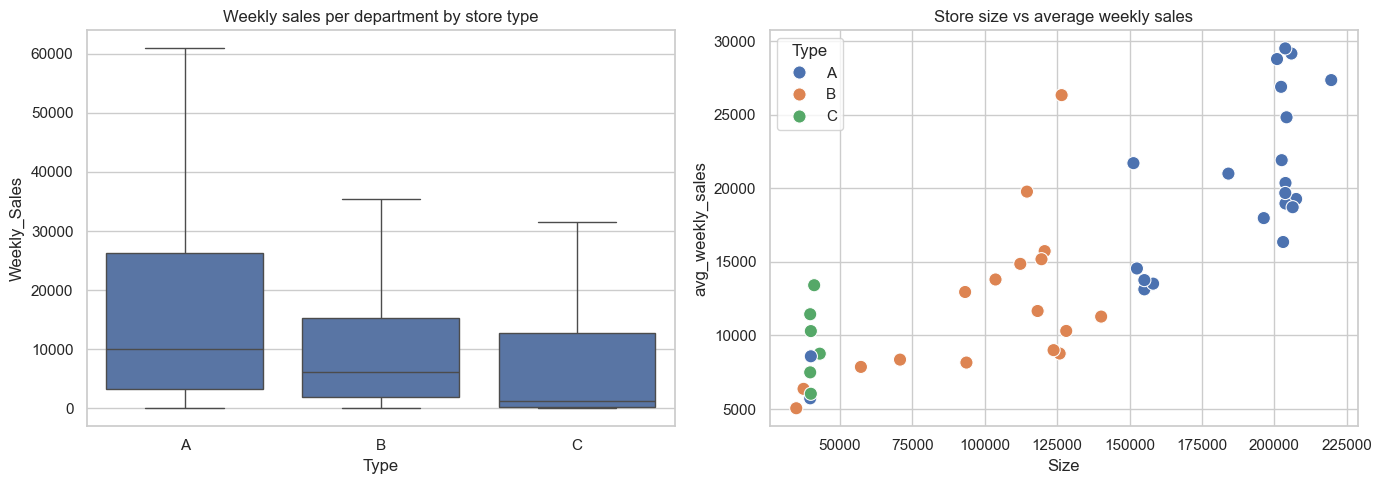

Correlation of store size with average sales: 0.81
      count     mean
Type                
A        22  19626.0
B        17  12088.0
C         6   9575.0


In [10]:
store_stats = df.groupby("Store").agg(
    avg_weekly_sales=("Weekly_Sales", "mean"),
    Size=("Size", "first"),
    Type=("Type", "first"),
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="Type", y="Weekly_Sales", ax=axes[0], showfliers=False, order=["A", "B", "C"])
axes[0].set_title("Weekly sales per department by store type")
sns.scatterplot(data=store_stats, x="Size", y="avg_weekly_sales", hue="Type", s=90, ax=axes[1])
axes[1].set_title("Store size vs average weekly sales")
plt.tight_layout()
plt.savefig("outputs/04_store_type_size.png", dpi=150, bbox_inches="tight")
plt.show()

print("Correlation of store size with average sales:",
      round(store_stats["Size"].corr(store_stats["avg_weekly_sales"]), 2))
print(store_stats.groupby("Type")["avg_weekly_sales"].agg(["count", "mean"]).round(0))

Interpretation: Bigger stores sell more (correlation 0.81 between store size and average sales). Type A stores sell the most (about 19,600 per department per week), then type B (about 12,100), then type C (about 9,600).

### 3.5 Top stores and departments

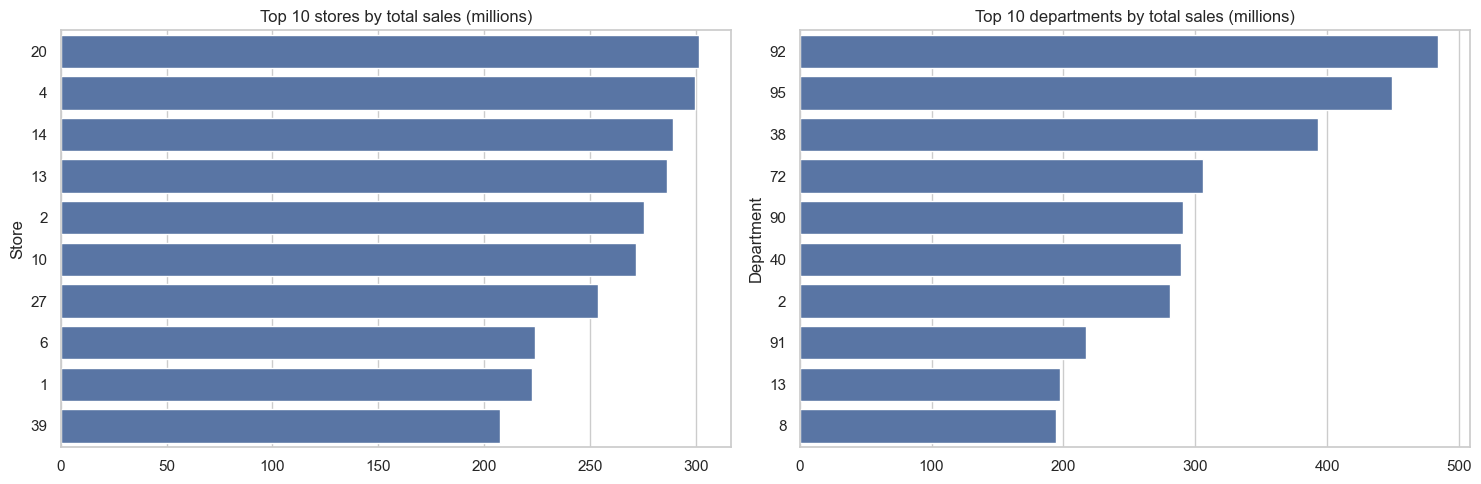

The top 10 departments produce 46% of all sales


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
top_stores = df.groupby("Store")["Weekly_Sales"].sum().nlargest(10).div(1e6)
sns.barplot(x=top_stores.values, y=top_stores.index.astype(str), ax=axes[0], orient="h")
axes[0].set_title("Top 10 stores by total sales (millions)")
axes[0].set_ylabel("Store")

top_depts = df.groupby("Dept")["Weekly_Sales"].sum().nlargest(10).div(1e6)
sns.barplot(x=top_depts.values, y=top_depts.index.astype(str), ax=axes[1], orient="h")
axes[1].set_title("Top 10 departments by total sales (millions)")
axes[1].set_ylabel("Department")
plt.tight_layout()
plt.savefig("outputs/05_top_stores_depts.png", dpi=150, bbox_inches="tight")
plt.show()

share = top_depts.sum() / (df["Weekly_Sales"].sum() / 1e6)
print(f"The top 10 departments produce {share:.0%} of all sales")

*Interpretation:* Interpretation: Sales are concentrated. The top 10 departments produce 46% of all sales. Stores 20, 4, 14, 13, 2 and 10 are the biggest. Departments 92, 95, 38, 72, 90 and 40 are the biggest. Planning should focus on these.

### 3.6 External factors and markdowns

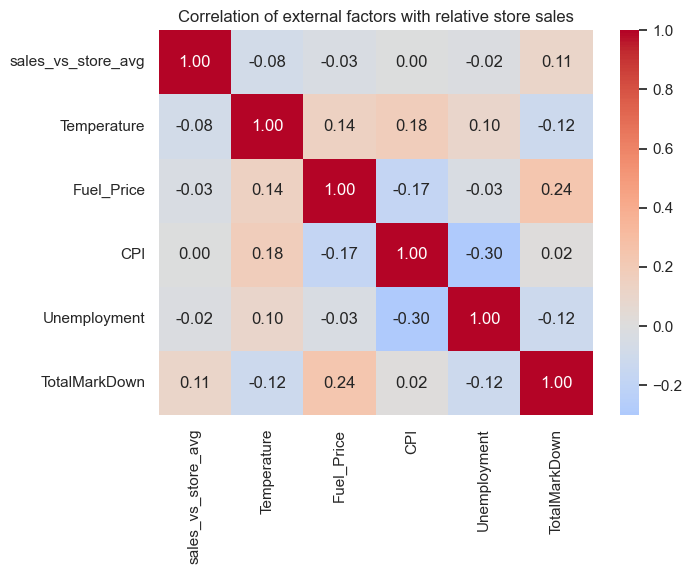

In [12]:
sw = df.groupby(["Store", "Date"]).agg(
    sales=("Weekly_Sales", "sum"),
    Temperature=("Temperature", "first"),
    Fuel_Price=("Fuel_Price", "first"),
    CPI=("CPI", "first"),
    Unemployment=("Unemployment", "first"),
    TotalMarkDown=("MarkDown1", "first"),
).reset_index()
for c in ["MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5"]:
    sw["TotalMarkDown"] += df.groupby(["Store", "Date"])[c].first().values

# Sales differ a lot between stores, so compare each store's sales with its own average
sw["sales_vs_store_avg"] = sw["sales"] / sw.groupby("Store")["sales"].transform("mean")

cols = ["sales_vs_store_avg", "Temperature", "Fuel_Price", "CPI", "Unemployment", "TotalMarkDown"]
plt.figure(figsize=(7, 5))
sns.heatmap(sw[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of external factors with relative store sales")
plt.savefig("outputs/06_external_factors.png", dpi=150, bbox_inches="tight")
plt.show()

*Interpretation:* Interpretation: External factors have very weak effects on sales. The correlations are small: markdowns +0.11, temperature -0.08, fuel price -0.03, unemployment -0.02 and CPI 0.00. Markdown data exists only from November 2011, so I do not draw strong conclusions from it.

## 4. Feature engineering
- **Date features:** month, week of year, quarter.
- **Holiday flags:** one for each named holiday plus the general flag.
- **Lag features:** sales 1, 2, 3, 4 and 52 weeks earlier for the same store and department, and the 4-week average. Lags are looked up by *date*, not by row position, so gaps in a series cannot shift them.

**Important assumption:** the lags mean we forecast **one week ahead** using actual recent sales, like a store that updates its forecast every week. A longer horizon would need larger lags.

In [13]:
def add_lag(frame, lag):
    src = frame[["Store", "Dept", "Date", "Weekly_Sales"]].copy()
    src["Date"] = src["Date"] + pd.Timedelta(weeks=lag)
    src = src.rename(columns={"Weekly_Sales": f"lag_{lag}"})
    return frame.merge(src, on=["Store", "Dept", "Date"], how="left")

fe = df.copy()
fe["Month"] = fe["Date"].dt.month
fe["Quarter"] = fe["Date"].dt.quarter
fe["WeekOfYear"] = fe["Date"].dt.isocalendar().week.astype(int)
for h in ["Super Bowl", "Labor Day", "Thanksgiving", "Christmas"]:
    fe["hol_" + h.replace(" ", "")] = (fe["HolidayName"] == h).astype(int)
fe["Type_code"] = fe["Type"].map({"A": 0, "B": 1, "C": 2})

for lag in [1, 2, 3, 4, 52]:
    fe = add_lag(fe, lag)
fe["roll_mean_4"] = fe[["lag_1", "lag_2", "lag_3", "lag_4"]].mean(axis=1)
fe = fe.drop(columns=["lag_3"])

lag_cols = ["lag_1", "lag_2", "lag_4", "lag_52", "roll_mean_4"]
before = len(fe)
model_df = fe.dropna(subset=lag_cols).copy()
print(f"Rows with a full history: {len(model_df):,} of {before:,} "
      f"({len(model_df) / before:.0%}). The first 52 weeks cannot have a 1-year lag.")

Rows with a full history: 257,788 of 421,570 (61%). The first 52 weeks cannot have a 1-year lag.


In [14]:
FEATURES = [
    "Store", "Dept", "Size", "Type_code",
    "Month", "Quarter", "WeekOfYear",
    "IsHoliday", "hol_SuperBowl", "hol_LaborDay", "hol_Thanksgiving", "hol_Christmas",
    "Temperature", "Fuel_Price", "CPI", "Unemployment",
    "MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5",
    "lag_1", "lag_2", "lag_4", "lag_52", "roll_mean_4",
]
TARGET = "Weekly_Sales"
assert model_df[FEATURES].isna().sum().sum() == 0, "NaNs in features"
print(len(FEATURES), "features")

26 features


## 5. Time-based train/test split
The most recent `TEST_WEEKS` weeks are the test set. Nothing from the test period is used for training.

In [15]:
dates = np.sort(model_df["Date"].unique())
cutoff = dates[-TEST_WEEKS - 1]          # last training week
train_df = model_df[model_df["Date"] <= cutoff]
test_df = model_df[model_df["Date"] > cutoff]

assert train_df["Date"].max() < test_df["Date"].min(), "Leakage: train and test overlap in time"
print("Train:", train_df["Date"].min().date(), "to", train_df["Date"].max().date(), f"({len(train_df):,} rows)")
print("Test :", test_df["Date"].min().date(), "to", test_df["Date"].max().date(), f"({len(test_df):,} rows)")
print("Holiday weeks in the test period:", sorted(test_df.loc[test_df['IsHoliday'] == 1, 'HolidayName'].unique()))

Train: 2011-02-04 to 2012-04-27 (184,043 rows)
Test : 2012-05-04 to 2012-10-26 (73,745 rows)
Holiday weeks in the test period: ['Labor Day']


## 6. Baselines and evaluation metrics
**MAE** is the average error in dollars; **RMSE** punishes large misses more; **WMAE** is the Kaggle metric where holiday weeks have weight 5.

In [16]:
def wmae(y_true, y_pred, is_holiday):
    w = np.where(is_holiday == 1, 5, 1)
    return np.sum(w * np.abs(y_true - y_pred)) / np.sum(w)

def evaluate(name, y_true, y_pred, is_holiday):
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "WMAE": wmae(y_true.values, np.asarray(y_pred), is_holiday.values),
    }

y_test = test_df[TARGET]
hol_test = test_df["IsHoliday"]
results = []
predictions = {}

# Baseline 1: same as last week. Baseline 2: same week last year. Baseline 3: 4-week average
for name, col in [("Naive (last week)", "lag_1"),
                  ("Seasonal naive (same week last year)", "lag_52"),
                  ("4-week moving average", "roll_mean_4")]:
    predictions[name] = test_df[col].values
    results.append(evaluate(name, y_test, predictions[name], hol_test))

pd.DataFrame(results).round(0)

,Model,MAE,RMSE,WMAE
0,Naive (last week),1607.0,3513.0,1685.0
1,Seasonal naive (same week last year),1765.0,3588.0,1775.0
2,4-week moving average,1621.0,3504.0,1675.0


## 7. Machine-learning models

In [17]:
X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test = test_df[FEATURES]

# 1. Ridge regression (a simple linear model, scaled inputs)
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
ridge.fit(X_train, y_train)
predictions["Ridge regression"] = np.clip(ridge.predict(X_test), 0, None)

# 2. Random forest (trained on a sample of up to 150k rows to keep it fast)
sample = train_df.sample(n=min(150_000, len(train_df)), random_state=RANDOM_STATE)
rf = RandomForestRegressor(n_estimators=100, max_depth=18, min_samples_leaf=3,
                           n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(sample[FEATURES], sample[TARGET])
predictions["Random forest"] = np.clip(rf.predict(X_test), 0, None)

# 3. Gradient boosting (fast histogram version from scikit-learn)
hgb = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, max_leaf_nodes=63,
                                    random_state=RANDOM_STATE)
hgb.fit(X_train, y_train)
predictions["Gradient boosting"] = np.clip(hgb.predict(X_test), 0, None)

for name in ["Ridge regression", "Random forest", "Gradient boosting"]:
    results.append(evaluate(name, y_test, predictions[name], hol_test))

results_df = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
results_df.round(0)

  File "C:\Users\muhsi\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\muhsi\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Program Files\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Program Files\Python313\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gi

,Model,MAE,RMSE,WMAE
0,Random forest,1294.0,2632.0,1309.0
1,Gradient boosting,1423.0,2849.0,1455.0
2,Ridge regression,1483.0,2927.0,1507.0
3,Naive (last week),1607.0,3513.0,1685.0
4,4-week moving average,1621.0,3504.0,1675.0
5,Seasonal naive (same week last year),1765.0,3588.0,1775.0


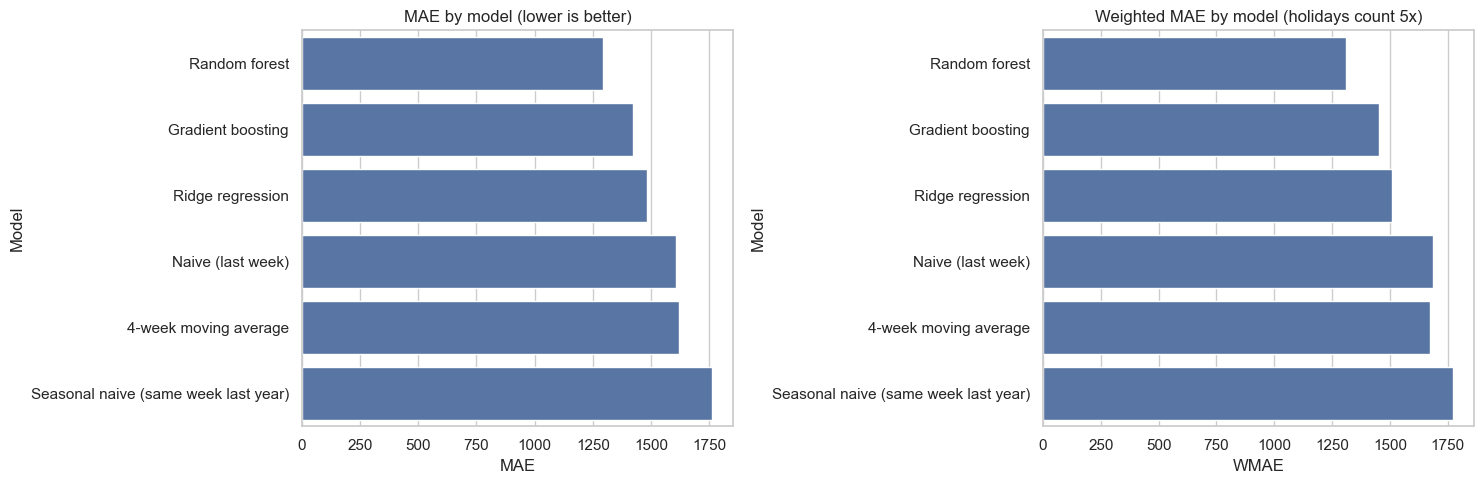

Best model: Random forest (MAE 1,294)
Improvement over the naive last-week baseline: 19.5%


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
order = results_df["Model"]
sns.barplot(data=results_df, y="Model", x="MAE", order=order, ax=axes[0])
axes[0].set_title("MAE by model (lower is better)")
sns.barplot(data=results_df, y="Model", x="WMAE", order=order, ax=axes[1])
axes[1].set_title("Weighted MAE by model (holidays count 5x)")
plt.tight_layout()
plt.savefig("outputs/07_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

best_name = results_df.loc[results_df["MAE"].idxmin(), "Model"]
base_mae = results_df.loc[results_df["Model"] == "Naive (last week)", "MAE"].iloc[0]
best_mae = results_df["MAE"].min()
print(f"Best model: {best_name} (MAE {best_mae:,.0f})")
print(f"Improvement over the naive last-week baseline: {(1 - best_mae / base_mae):.1%}")

*Interpretation:* Interpretation: Random forest is the best model (MAE 1,294). It is 19.5% better than the simple "same as last week" baseline (MAE 1,607). Gradient boosting and Ridge also beat the baselines. "Same week last year" alone is the weakest (MAE 1,765).

## 8. Time-series model on total sales (Holt-Winters)
Holt-Winters models trend and yearly seasonality directly. It needs at least two years of weekly data, so it is fitted on the **total weekly sales** across all stores.

*Fair-comparison note:* Holt-Winters forecasts the whole test period from the training data alone (a long horizon), while the ML models get updated sales every week (1 week ahead). The ML models therefore have an easier task, so compare these numbers with care.

In [19]:
try:
    from statsmodels.tsa.holtwinters import ExponentialSmoothing
    HAVE_STATSMODELS = True
except ImportError:
    HAVE_STATSMODELS = False
    print("statsmodels is not installed. Run:  pip install statsmodels   then re-run this cell.")

hw_forecast = None
if HAVE_STATSMODELS:
    series = weekly.asfreq("W-FRI")                    # weekly series ending on Fridays
    test_dates = pd.DatetimeIndex(sorted(test_df["Date"].unique()))
    train_series = series[series.index <= pd.Timestamp(cutoff)]
    try:
        hw = ExponentialSmoothing(train_series, trend="add", seasonal="mul", seasonal_periods=52,
                                  initialization_method="estimated").fit()
    except Exception as e:
        print("Multiplicative seasonality failed (", e, "), using additive seasonality")
        hw = ExponentialSmoothing(train_series, trend="add", seasonal="add", seasonal_periods=52,
                                  initialization_method="estimated").fit()
    hw_forecast = hw.forecast(len(test_dates))
    hw_forecast.index = test_dates
    print("Holt-Winters fitted on", len(train_series), "weeks; forecasting", len(test_dates), "weeks")

Holt-Winters fitted on 117 weeks; forecasting 26 weeks


In [20]:
# Compare everything at the level of total weekly sales over the test period
actual_total = test_df.groupby("Date")[TARGET].sum()

rows = []
for name, pred in predictions.items():
    pred_total = pd.Series(pred, index=test_df.index).groupby(test_df["Date"]).sum()
    rows.append({"Model": name,
                 "Total-sales MAE": mean_absolute_error(actual_total, pred_total),
                 "Total-sales MAPE %": np.mean(np.abs(actual_total - pred_total) / actual_total) * 100})
if hw_forecast is not None:
    full_actual = weekly.loc[hw_forecast.index]
    rows.append({"Model": "Holt-Winters (long horizon)",
                 "Total-sales MAE": mean_absolute_error(full_actual, hw_forecast),
                 "Total-sales MAPE %": np.mean(np.abs(full_actual - hw_forecast) / full_actual) * 100})
total_results = pd.DataFrame(rows).sort_values("Total-sales MAE").reset_index(drop=True)
total_results.round(1)

,Model,Total-sales MAE,Total-sales MAPE %
0,Ridge regression,898853.2,1.9
1,Random forest,907039.9,1.9
2,Holt-Winters (long horizon),1013948.9,2.2
3,Seasonal naive (same week last year),1170651.1,2.5
4,Gradient boosting,1412383.2,3.0
5,Naive (last week),1460597.5,3.1
6,4-week moving average,1489492.7,3.2


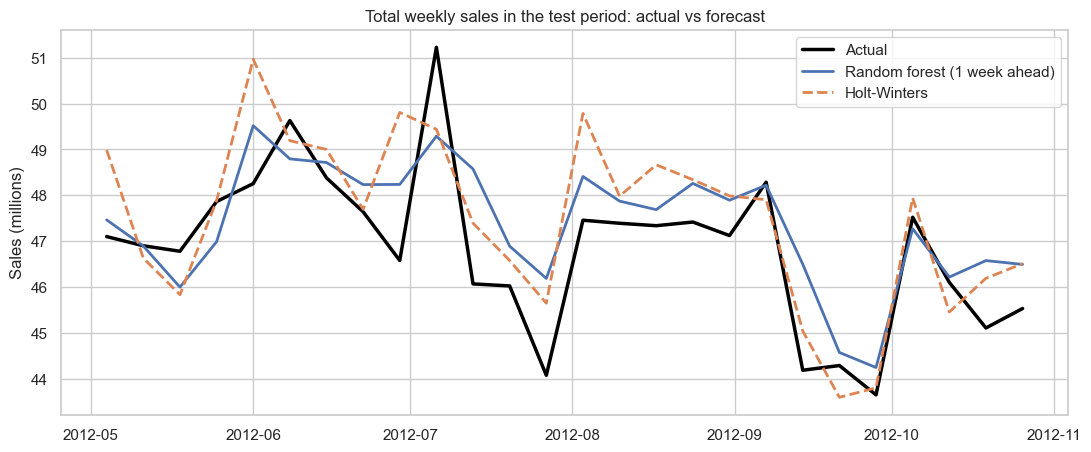

In [21]:
plt.figure(figsize=(13, 5))
plt.plot(actual_total.index, actual_total / 1e6, label="Actual", lw=2.5, color="black")
best_pred_total = pd.Series(predictions[best_name], index=test_df.index).groupby(test_df["Date"]).sum()
plt.plot(best_pred_total.index, best_pred_total / 1e6, label=f"{best_name} (1 week ahead)", lw=2)
if hw_forecast is not None:
    plt.plot(hw_forecast.index, hw_forecast / 1e6, label="Holt-Winters", lw=2, ls="--")
plt.title("Total weekly sales in the test period: actual vs forecast")
plt.ylabel("Sales (millions)")
plt.legend()
plt.savefig("outputs/08_actual_vs_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

*Interpretation:* Interpretation: The models follow the weekly ups and downs well. For total weekly sales, the error is only about 2% (Ridge 1.9%, random forest 1.9%, Holt-Winters 2.2%). All models miss the sharp peak in July and some dips in August and September.

## 9. What drives the forecasts? Feature importance

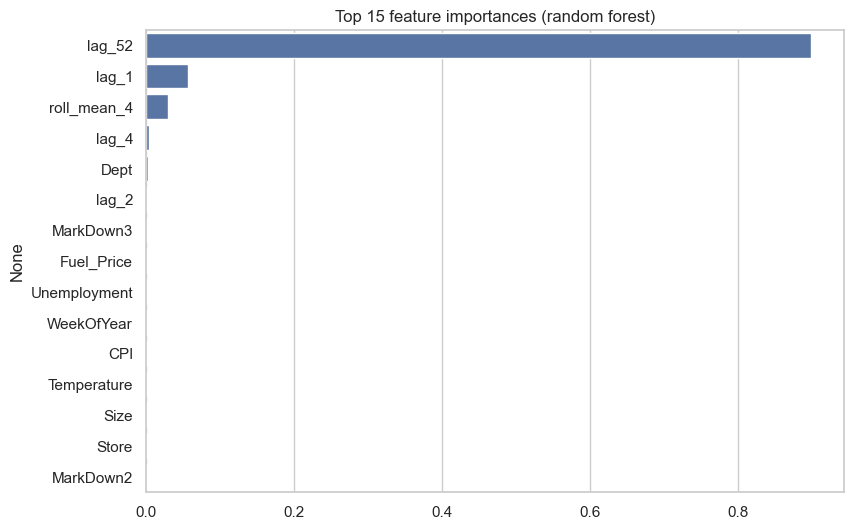

lag_52          0.898
lag_1           0.056
roll_mean_4     0.029
lag_4           0.004
Dept            0.002
lag_2           0.001
MarkDown3       0.001
Fuel_Price      0.001
Unemployment    0.001
WeekOfYear      0.001
CPI             0.001
Temperature     0.001
Size            0.001
Store           0.001
MarkDown2       0.000
dtype: float64


In [22]:
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=False).head(15)
plt.figure(figsize=(9, 6))
sns.barplot(x=imp.values, y=imp.index, orient="h")
plt.title("Top 15 feature importances (random forest)")
plt.savefig("outputs/09_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
print(imp.round(3))

*Interpretation:* Interpretation: Last year's sales in the same week (lag_52) is the most important feature (0.90). Last week's sales (lag_1) is second. Department, store size, temperature and other features add very little.

## 10. Where does the best model go wrong? Error analysis

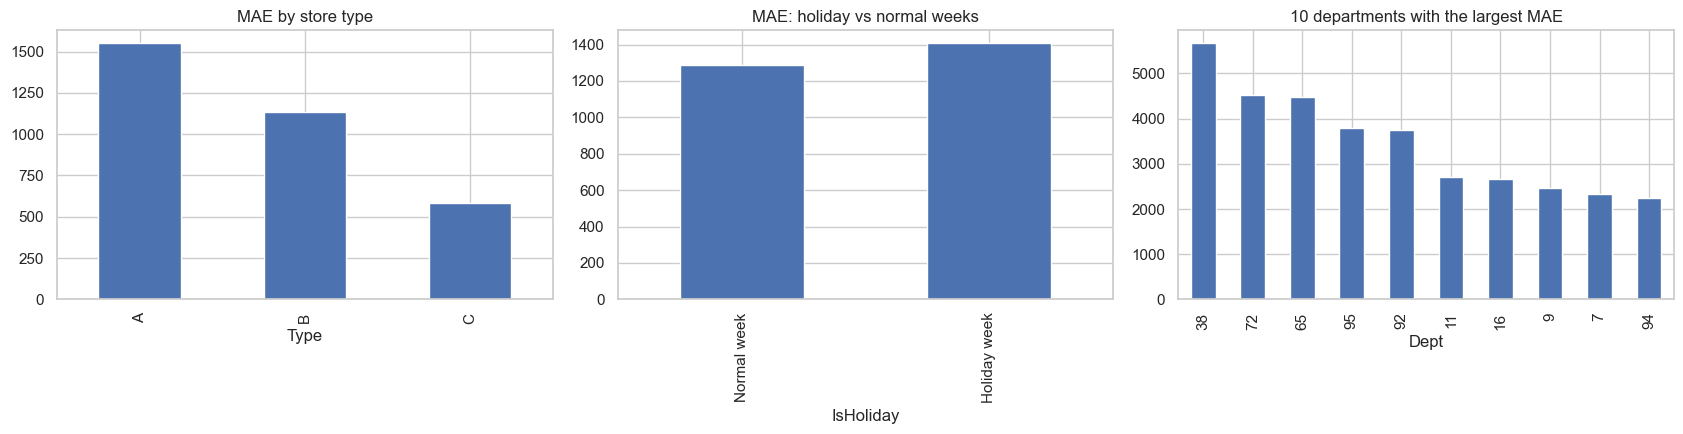

In [23]:
err = test_df[["Store", "Dept", "Date", "Type", "HolidayName", "IsHoliday", TARGET]].copy()
err["pred"] = predictions[best_name]
err["abs_error"] = (err[TARGET] - err["pred"]).abs()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
err.groupby("Type")["abs_error"].mean().plot(kind="bar", ax=axes[0])
axes[0].set_title("MAE by store type")

err.groupby("IsHoliday")["abs_error"].mean().rename({0: "Normal week", 1: "Holiday week"}).plot(kind="bar", ax=axes[1])
axes[1].set_title("MAE: holiday vs normal weeks")

err.groupby("Dept")["abs_error"].mean().nlargest(10).plot(kind="bar", ax=axes[2])
axes[2].set_title("10 departments with the largest MAE")
plt.tight_layout()
plt.savefig("outputs/10_error_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

err.to_csv("outputs/test_predictions.csv", index=False)

*Interpretation:* Interpretation: Errors in dollars are larger for type A stores, which are the biggest. Holiday weeks have slightly larger errors than normal weeks. Departments 38, 72, 65, 95 and 92 are the hardest to predict, and several of them are also top-selling departments.

## 11. Summary dashboard

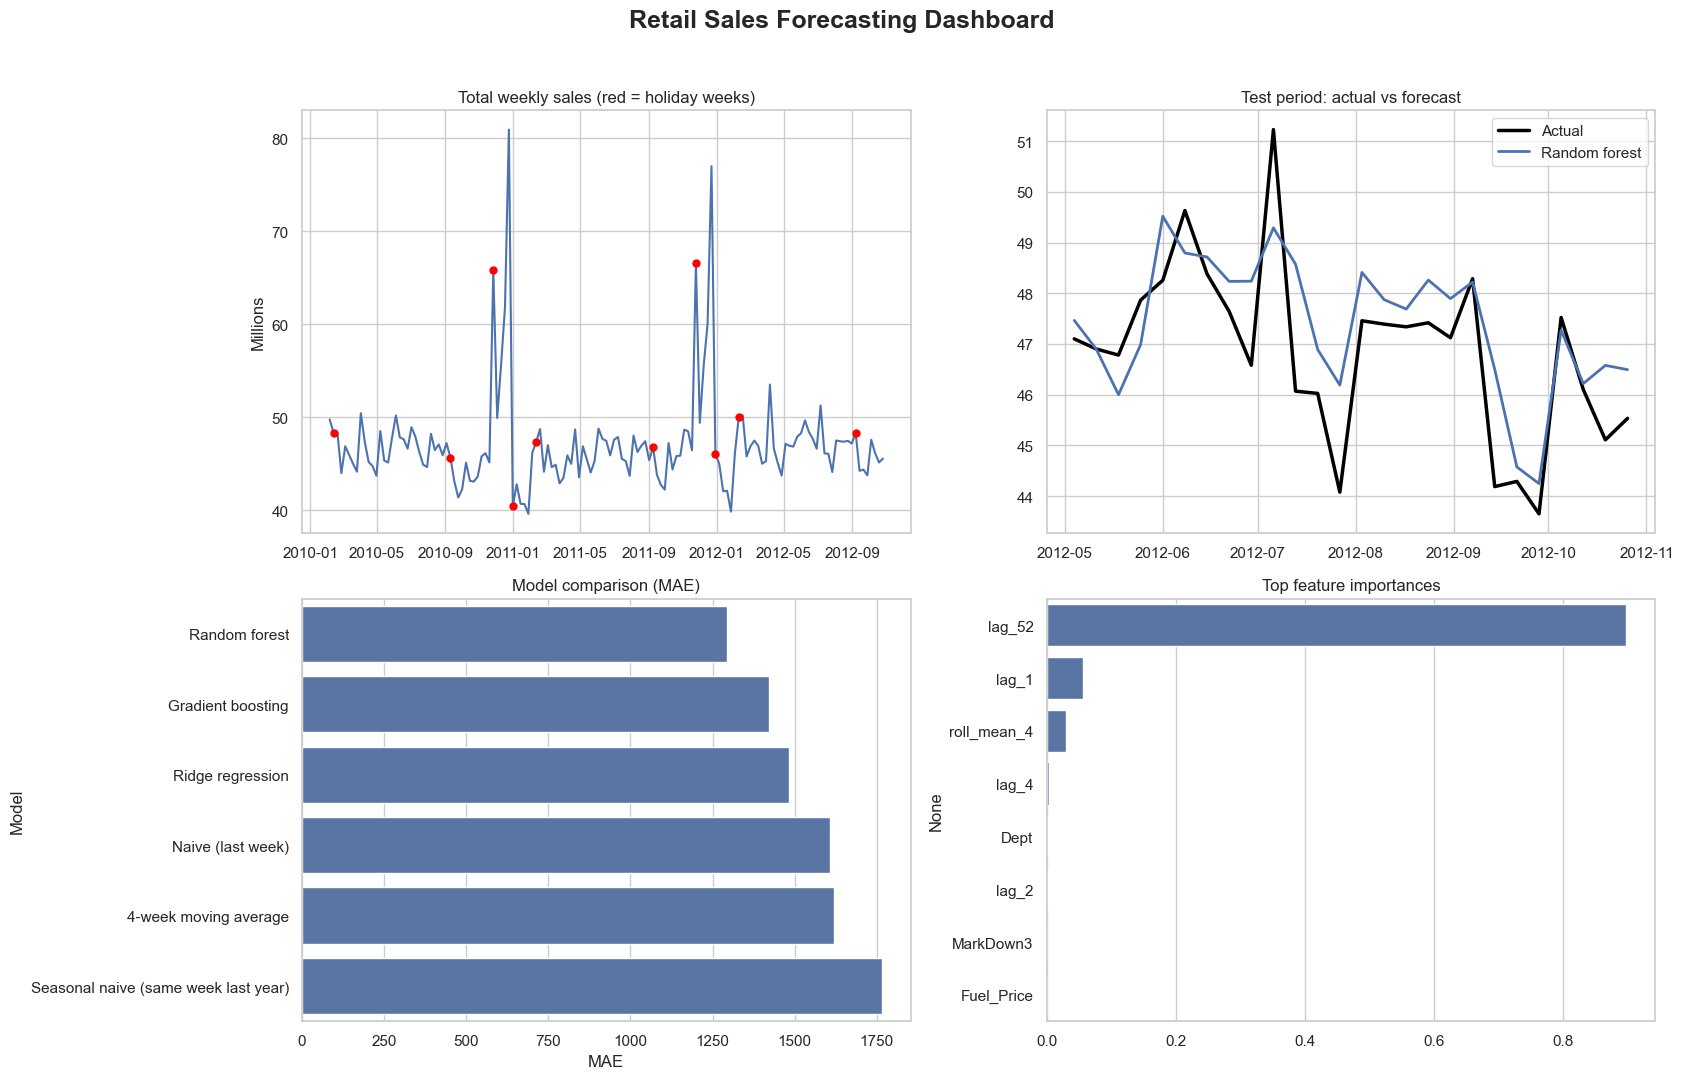

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(17, 11))
fig.suptitle("Retail Sales Forecasting Dashboard", fontsize=18, fontweight="bold")

axes[0, 0].plot(weekly.index, weekly.values / 1e6)
axes[0, 0].scatter(hol.index, hol.values / 1e6, color="red", zorder=3, s=25)
axes[0, 0].set_title("Total weekly sales (red = holiday weeks)")
axes[0, 0].set_ylabel("Millions")

axes[0, 1].plot(actual_total.index, actual_total / 1e6, color="black", lw=2.5, label="Actual")
axes[0, 1].plot(best_pred_total.index, best_pred_total / 1e6, lw=2, label=best_name)
axes[0, 1].set_title("Test period: actual vs forecast")
axes[0, 1].legend()

sns.barplot(data=results_df, y="Model", x="MAE", order=results_df["Model"], ax=axes[1, 0])
axes[1, 0].set_title("Model comparison (MAE)")

sns.barplot(x=imp.head(8).values, y=imp.head(8).index, orient="h", ax=axes[1, 1])
axes[1, 1].set_title("Top feature importances")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("outputs/00_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Insights and recommendations


| # | Insight | Evidence | Recommendation |
|---|---|---|---|
| 1 | Sales are strongly seasonal | December about 58M a week vs about 42M in January | Build stock and staff before November and December |
| 2 | Thanksgiving week lifts sales | 41.3% higher than a normal week | Plan extra stock and staff for Thanksgiving week and the week before Christmas |
| 3 | A few departments drive sales | Top 10 departments make 46% of all sales | Keep these departments well stocked |
| 4 | Last year's and last week's sales are the best predictors | lag_52 = 0.90, lag_1 = 0.06 | Update forecasts every week |
| 5 | The model beats simple baselines | MAE 1,294 vs 1,607 (19.5% better) | Use the model for weekly ordering |
| 6 | Errors are highest in big departments and holiday weeks | Departments 38, 72, 65, 95 and 92 | Add human review for these |

## 13. Limitations
- The Kaggle `test.csv` has no sales values, so the last 26 weeks of `train.csv` were held out instead.
- The test period (Apr to Oct 2012) does **not** include the Thanksgiving or Christmas peaks, which are the hardest weeks to forecast. Say this clearly in your README.
- The ML models forecast one week ahead using actual recent sales. A longer-horizon forecast would be less accurate.
- Markdown data only exists from Nov 2011, and external factors (temperature, fuel price, CPI) have weak effects.
- Only about three years of data, so yearly seasonality is learned from at most two cycles.